# Rozdział 5 — Grupowanie klientów
Wczytanie cech, metoda łokcia, sylwetka, k-średnich, DBSCAN, PCA, profilowanie.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
K_FINAL_PLANNED = 3   # liczba skupisk przyjeta w rozdz. 5.1.1
plt.rcParams.update({'figure.dpi': 150, 'font.size': 11})

# Wczytanie danych
rfm = pd.read_csv('rfm_features.csv')
X = pd.read_csv('rfm_scaled.csv').values

print(f'Macierz cech: {X.shape}')
print(f'Klientów: {len(rfm)}')
pd.read_csv('rfm_scaled.csv').describe().round(2)

Macierz cech: (5859, 8)
Klientów: 5859


,Recency,Frequency,Monetary,ProductDiversity,AvgOrderValue,PreferredHour,PreferredDay,AvgDaysBetweenPurchases
count,5859.00,5859.00,5859.00,5859.00,5859.00,5859.00,5859.00,5859.00
mean,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.41,-1.06,-3.95,-2.53,-5.84,-2.47,-1.37,-3.77
25%,-0.74,-1.06,-0.71,-0.63,-0.59,-0.70,-0.84,-0.60
50%,0.08,-0.20,-0.03,0.05,0.03,0.19,-0.30,-0.03
75%,0.95,0.66,0.66,0.73,0.56,0.63,0.77,0.75
max,1.38,5.44,4.70,3.37,5.84,3.29,1.83,1.69


## 1. K-średnich — metoda łokcia i współczynniki sylwetki

In [2]:
K_RANGE = range(2, 13)

inertia = []
silhouette = []
ch_scores = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, labels))
    ch_scores.append(calinski_harabasz_score(X, labels))
    print(f'k={k:2d}  inercja={km.inertia_:10.1f}  '
          f'sylwetka={silhouette[-1]:.4f}  CH={ch_scores[-1]:.1f}')

print('\nGotowe.')

k= 2  inercja=   33780.4  sylwetka=0.2395  CH=2269.9


k= 3  inercja=   29742.9  sylwetka=0.1668  CH=1686.3


k= 4  inercja=   27263.3  sylwetka=0.1656  CH=1403.7


k= 5  inercja=   25325.5  sylwetka=0.1648  CH=1245.1


k= 6  inercja=   23752.0  sylwetka=0.1632  CH=1139.5


...

k= 8  inercja=   21463.6  sylwetka=0.1438  CH=989.5


k= 9  inercja=   20565.4  sylwetka=0.1410  CH=935.4


k=10  inercja=   19771.8  sylwetka=0.1393  CH=890.8


k=11  inercja=   19106.7  sylwetka=0.1352  CH=849.8


k=12  inercja=   18488.5  sylwetka=0.1433  CH=816.0

Gotowe.


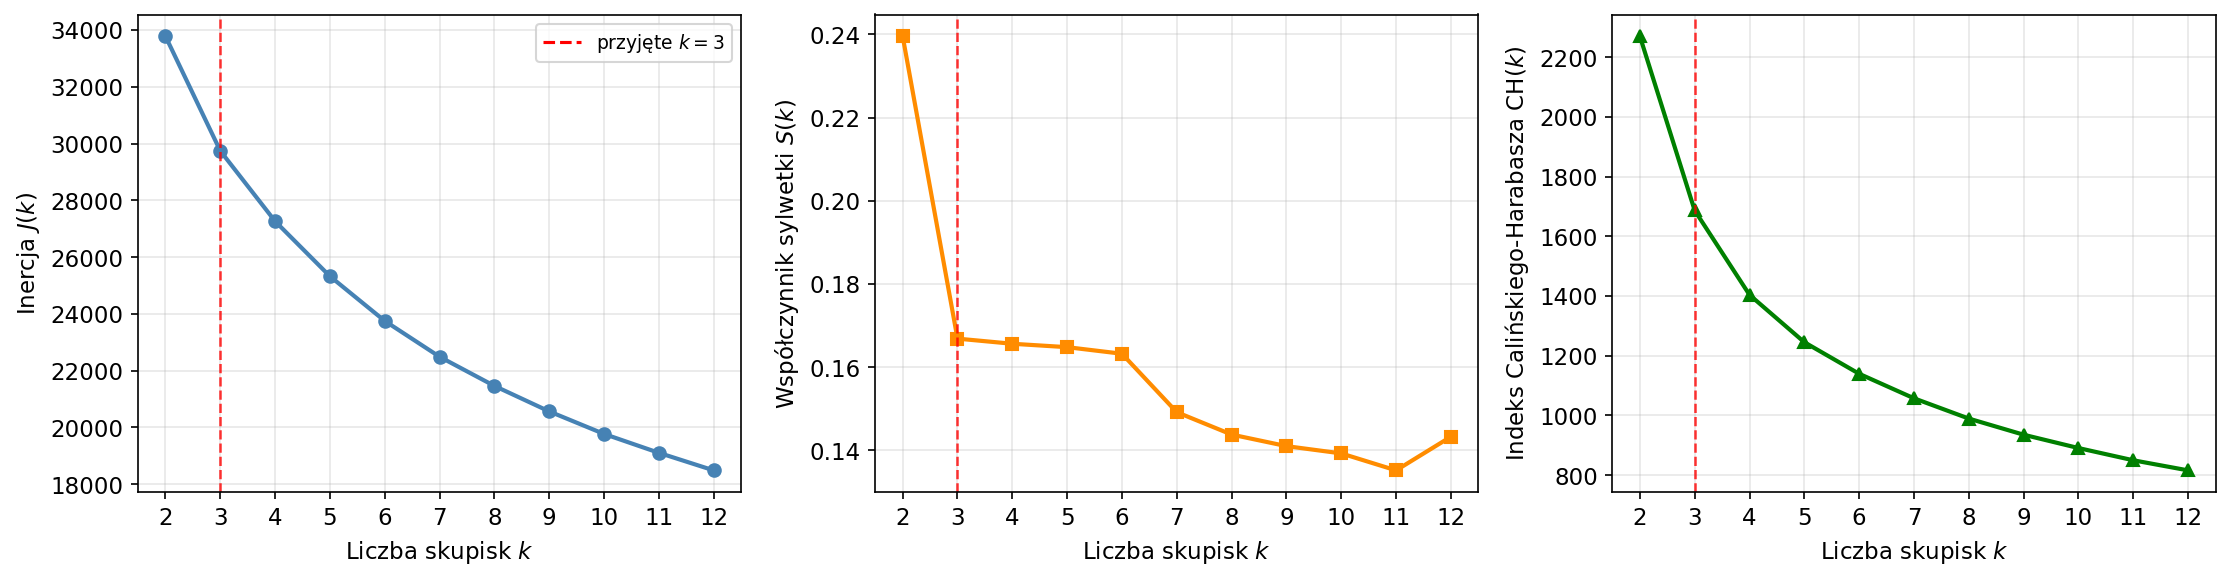

Zapisano: fig_lokciec.png

Względne spadki inercji:
  k= 2 -> k= 3:  11.95%
  k= 3 -> k= 4:   8.34%
  k= 4 -> k= 5:   7.11%
  k= 5 -> k= 6:   6.21%
  k= 6 -> k= 7:   5.31%
  k= 7 -> k= 8:   4.56%
  k= 8 -> k= 9:   4.18%
  k= 9 -> k=10:   3.86%
  k=10 -> k=11:   3.36%
  k=11 -> k=12:   3.24%


In [3]:
# Wykres doboru k -- bez tytulow nad panelami (tytul jest w podpisie rysunku
# w pracy). Nazwa miary trafia na os Y. Czerwona linia znaczy przyjete k = 3.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ks = list(K_RANGE)
specs = [
    (inertia,   r'Inercja $J(k)$',                                  'steelblue',  'o'),
    (silhouette, r'Współczynnik sylwetki $S(k)$',                   'darkorange', 's'),
    (ch_scores, r'Indeks Calińskiego-Harabasza $\mathrm{CH}(k)$',   'green',      '^'),
]

for ax, (vals, ylab, color, marker) in zip(axes, specs):
    ax.plot(ks, vals, marker=marker, color=color, linewidth=2)
    ax.axvline(K_FINAL_PLANNED, color='red', linestyle='--', linewidth=1.2, alpha=0.8)
    ax.set_xlabel('Liczba skupisk $k$')
    ax.set_ylabel(ylab)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax.grid(alpha=0.3)

axes[0].legend([plt.Line2D([], [], color='red', linestyle='--')],
               [f'przyjęte $k = {K_FINAL_PLANNED}$'], fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig('fig_lokciec.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_lokciec.png')

# Wzgledne spadki inercji -- cytowane w rozdz. 5.1.1 jako dowod braku ostrego lokcia
print('\nWzględne spadki inercji:')
for i in range(len(ks) - 1):
    d = (inertia[i] - inertia[i + 1]) / inertia[i] * 100
    print(f'  k={ks[i]:2d} -> k={ks[i+1]:2d}:  {d:5.2f}%')

## 2. K-średnich — model finalny z optymalnym k

In [4]:
# Wybierz k na podstawie wykresów powyżej.
# Domyślnie: k z najwyższą sylwetką lub widocznym łokciem.
best_k_sil = ks[int(np.argmax(silhouette))]
print(f'k z najwyższą sylwetką: {best_k_sil}  (S={max(silhouette):.4f})')

# Wartość k=2 maksymalizuje statystyki (sylwetka, CH), ale daje jedynie
# binarny podział aktywni/nieaktywni bez wartości interpretacyjnej ponad
# samą definicję churnu (patrz uzasadnienie w rozdz. 5.1.1). Przyjęto k=3
# jako kompromis między wartością statystyczną a interpretatywną.
K_FINAL = 3

km_final = KMeans(n_clusters=K_FINAL, init='k-means++', n_init=50,
                  random_state=RANDOM_STATE)
km_labels = km_final.fit_predict(X)

rfm['cluster_kmeans'] = km_labels
print(f'\nLiczba skupisk: {K_FINAL}')
print(f'Inercja finalna: {km_final.inertia_:.1f}')
print(f'Sylwetka finalna: {silhouette_score(X, km_labels):.4f}')
print(f'\nRozkład skupisk:')
print(rfm['cluster_kmeans'].value_counts().sort_index())

k z najwyższą sylwetką: 2  (S=0.2395)

Liczba skupisk: 3
Inercja finalna: 29742.9


Sylwetka finalna: 0.1668

Rozkład skupisk:
cluster_kmeans
0    1467
1    1663
2    2729
Name: count, dtype: int64


## 3. DBSCAN — wykres k-odległości i dobór eps

MinPts                      = 16
Punkt zagięcia (kolano)     = 1.7074   (indeks 426 z 5859)
Wartość przyjęta (5. perc.) = 0.7599   (indeks 5566 z 5859)


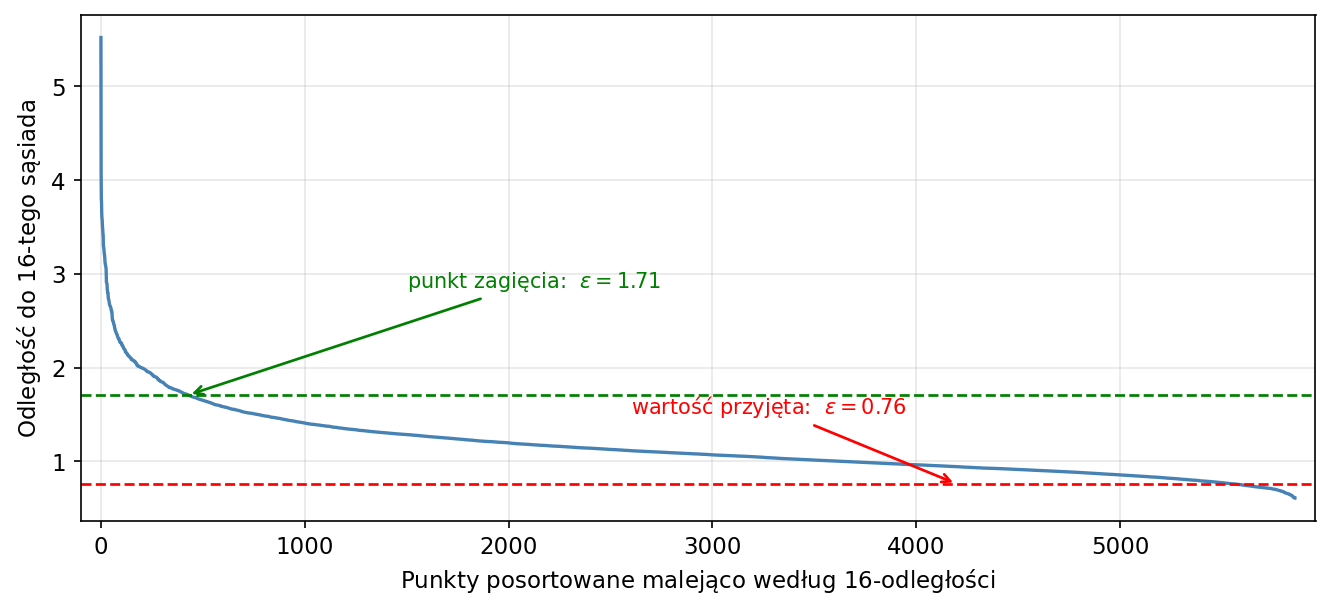

Zapisano: fig_kdistance.png


In [5]:
# MinPts = 2 * liczba cech (regula praktyczna, Ester i in. 1996)
N_FEATURES = X.shape[1]
MIN_PTS = 2 * N_FEATURES  # = 16

nbrs = NearestNeighbors(n_neighbors=MIN_PTS).fit(X)
distances, _ = nbrs.kneighbors(X)
k_distances = np.sort(distances[:, -1])[::-1]

# --- Punkt zagiecia krzywej wyznaczony ilosciowo -------------------------
# Metoda maksymalnej odleglosci od cieciwy laczacej konce krzywej
# (odpowiednik graficznego "kolana"). Wynik dokumentowany w rozdz. 5.2.
n_pts = len(k_distances)
xs = np.arange(n_pts, dtype=float)
x1, y1 = xs[0],  k_distances[0]
x2, y2 = xs[-1], k_distances[-1]
num = np.abs((y2 - y1) * xs - (x2 - x1) * k_distances + x2 * y1 - y2 * x1)
knee_idx = int(np.argmax(num / np.hypot(y2 - y1, x2 - x1)))
EPS_KNEE = float(k_distances[knee_idx])

# --- Wartosc ostatecznie przyjeta ----------------------------------------
# EPS_KNEE laczy niemal caly zbior w jedno skupisko (sprawdzone w komorce nizej),
# wiec aby DBSCAN wyodrebnil wiecej niz jedna grupe, eps trzeba obnizyc znacznie
# ponizej kolana. Przyjeto 5. percentyl rozkladu 16-odleglosci.
EPS = float(np.percentile(k_distances, 5))

print(f'MinPts                      = {MIN_PTS}')
print(f'Punkt zagięcia (kolano)     = {EPS_KNEE:.4f}   (indeks {knee_idx} z {n_pts})')
print(f'Wartość przyjęta (5. perc.) = {EPS:.4f}   '
      f'(indeks {int((k_distances >= EPS).sum())} z {n_pts})')

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(k_distances, color='steelblue', linewidth=1.6)
ax.axhline(EPS_KNEE, color='green', linestyle='--', linewidth=1.3)
ax.axhline(EPS,      color='red',   linestyle='--', linewidth=1.3)
ax.annotate(f'punkt zagięcia:  $\\varepsilon = {EPS_KNEE:.2f}$',
            xy=(knee_idx, EPS_KNEE), xytext=(1500, EPS_KNEE + 1.15),
            arrowprops=dict(arrowstyle='->', color='green', lw=1.3),
            color='green', fontsize=10)
ax.annotate(f'wartość przyjęta:  $\\varepsilon = {EPS:.2f}$',
            xy=(4200, EPS), xytext=(2600, EPS + 0.75),
            arrowprops=dict(arrowstyle='->', color='red', lw=1.3),
            color='red', fontsize=10)
ax.set_xlabel(f'Punkty posortowane malejąco według ${MIN_PTS}$-odległości')
ax.set_ylabel(f'Odległość do ${MIN_PTS}$-tego sąsiada')
ax.grid(alpha=0.3)
ax.set_xlim(-100, n_pts + 100)
plt.tight_layout()
plt.savefig('fig_kdistance.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_kdistance.png')

In [6]:
def opisz_dbscan(labels, nazwa):
    """Zestawienie liczby skupisk, szumu i miar jakosci dla podzialu DBSCAN."""
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    mask = labels != -1
    print(f'--- {nazwa} ---')
    print(f'  Skupisk: {n_cl}')
    print(f'  Szum:    {n_noise} z {len(labels)} ({n_noise / len(labels) * 100:.1f}%)')
    if n_cl >= 1:
        naj = pd.Series(labels[mask]).value_counts()
        print(f'  Największe skupisko: {naj.iloc[0]} obserwacji '
              f'({naj.iloc[0] / len(labels) * 100:.1f}%)')
    if n_cl > 1:
        print(f'  Sylwetka (bez szumu): {silhouette_score(X[mask], labels[mask]):.4f}')
        print(f'  CH       (bez szumu): {calinski_harabasz_score(X[mask], labels[mask]):.1f}')
    return n_cl, n_noise


# 1) DBSCAN w punkcie zagiecia krzywej k-odleglosci
db_knee_labels = DBSCAN(eps=EPS_KNEE, min_samples=MIN_PTS).fit_predict(X)
opisz_dbscan(db_knee_labels, f'eps = {EPS_KNEE:.2f} (punkt zagięcia)')

print()

# 2) DBSCAN przy wartosci przyjetej -- model raportowany w pracy
db = DBSCAN(eps=EPS, min_samples=MIN_PTS)
db_labels = db.fit_predict(X)
opisz_dbscan(db_labels, f'eps = {EPS:.2f} (wartość przyjęta)')

rfm['cluster_dbscan'] = db_labels

print('\nRozkład skupisk przy wartości przyjętej (-1 = szum):')
print(pd.Series(db_labels).value_counts().sort_index())

--- eps = 1.71 (punkt zagięcia) ---
  Skupisk: 1
  Szum:    124 z 5859 (2.1%)
  Największe skupisko: 5735 obserwacji (97.9%)

--- eps = 0.76 (wartość przyjęta) ---
  Skupisk: 7
  Szum:    5008 z 5859 (85.5%)
  Największe skupisko: 570 obserwacji (9.7%)
  Sylwetka (bez szumu): 0.2619
  CH       (bez szumu): 272.2

Rozkład skupisk przy wartości przyjętej (-1 = szum):
-1    5008
 0     570
 1     101
 2      76
 3      34
 4      19
 5      24
 6      27
Name: count, dtype: int64


## 4. Wizualizacja skupisk — PCA (2D)

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
var_explained = pca.explained_variance_ratio_
print(f'Wariancja wyjaśniona przez PC1: {var_explained[0]:.1%}')
print(f'Wariancja wyjaśniona przez PC2: {var_explained[1]:.1%}')
print(f'Łącznie: {sum(var_explained):.1%}')

Wariancja wyjaśniona przez PC1: 43.8%
Wariancja wyjaśniona przez PC2: 14.0%
Łącznie: 57.8%


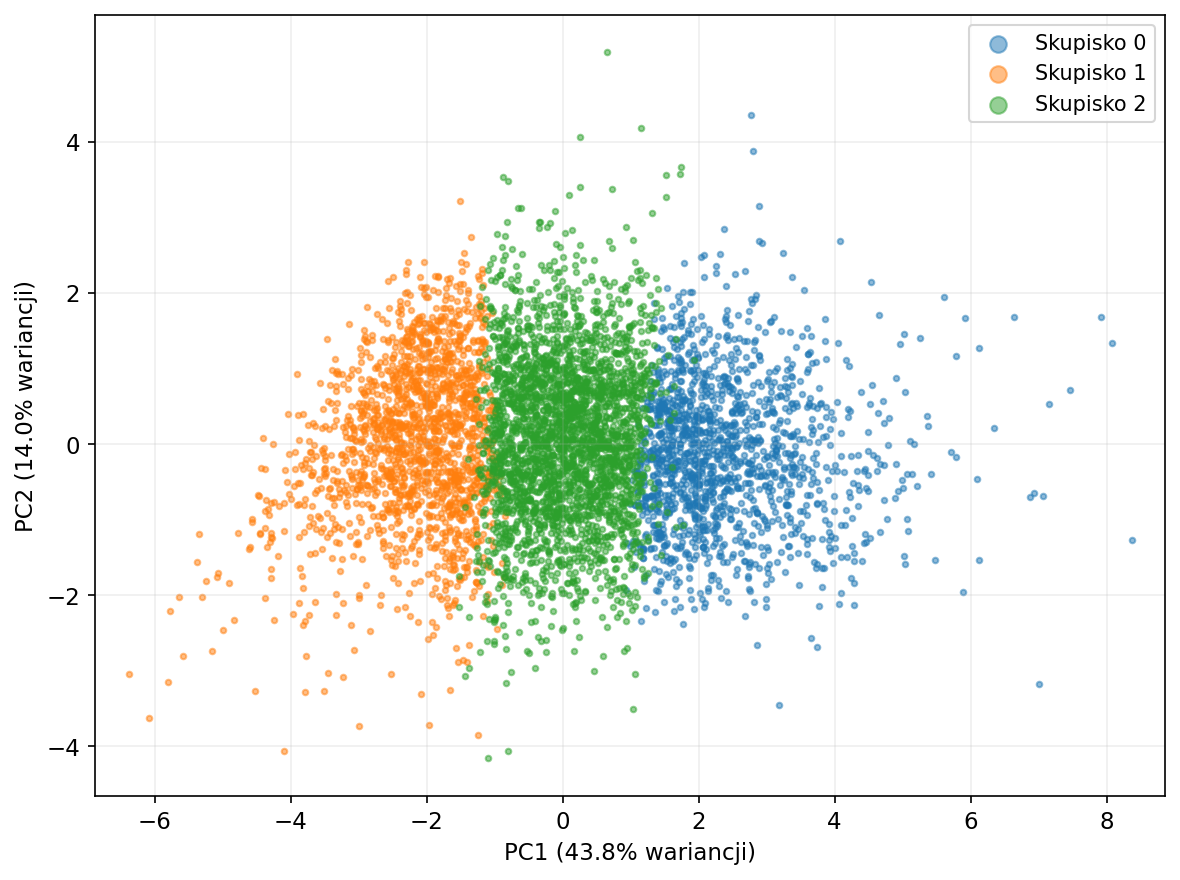

Zapisano: fig_pca_kmeans.png   ($k$-srednich, k = 3)


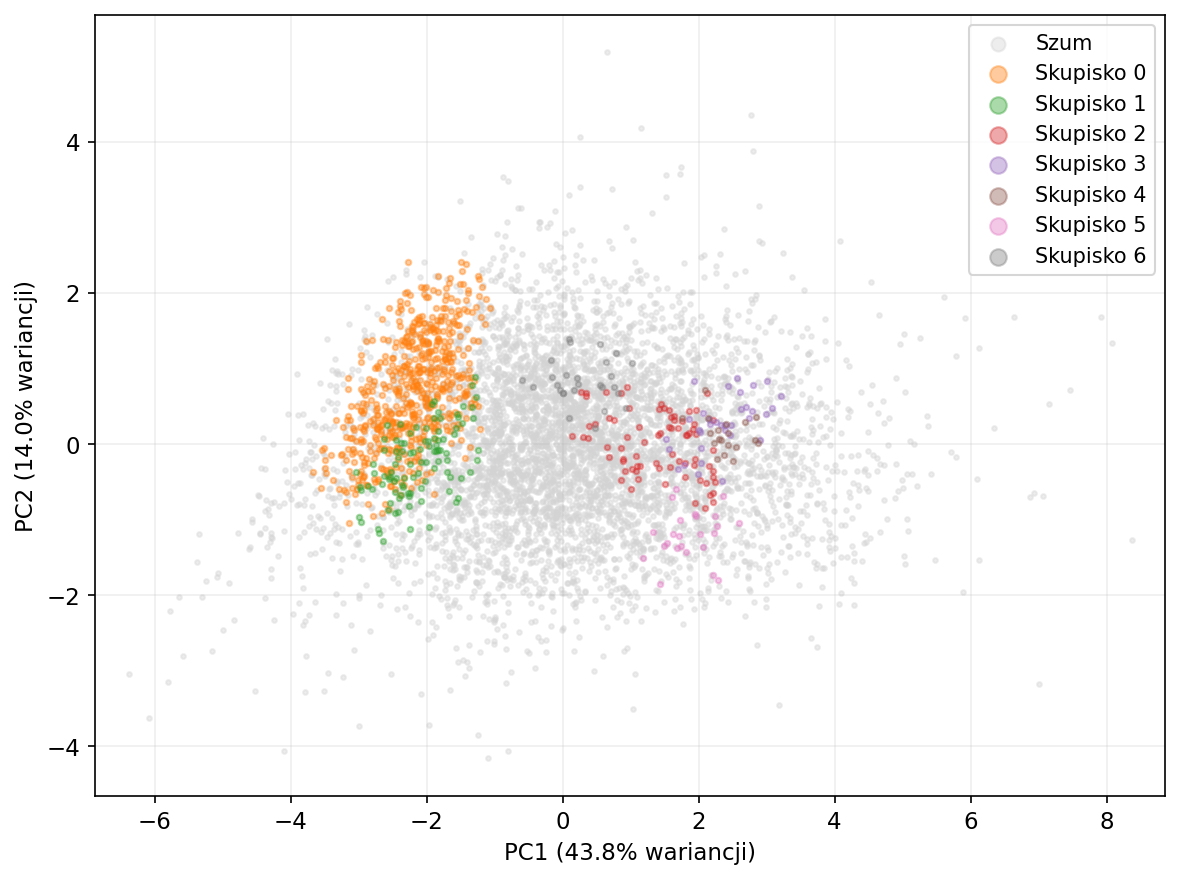

Zapisano: fig_pca_dbscan.png   (DBSCAN, eps = 0.76, MinPts = 16)


In [8]:
# Wizualizacja PCA -- dwa osobne rysunki: k-srednich (rozdz. 5.1.2)
# oraz DBSCAN (rozdz. 5.2). Wspolne zakresy osi, zeby oba byly porownywalne.
xlim = (X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5)
ylim = (X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5)

def opisz_osie(ax):
    ax.set_xlabel(f'PC1 ({var_explained[0]:.1%} wariancji)')
    ax.set_ylabel(f'PC2 ({var_explained[1]:.1%} wariancji)')
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.legend(markerscale=3, fontsize=10)
    ax.grid(alpha=0.2)

# --- rysunek 1: k-srednich ---
fig, ax = plt.subplots(figsize=(8, 6))
palette_km = sns.color_palette('tab10', K_FINAL)
for c in range(K_FINAL):
    mask = km_labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=7, alpha=0.5,
               color=palette_km[c], label=f'Skupisko {c}')
opisz_osie(ax)
plt.tight_layout()
plt.savefig('fig_pca_kmeans.png', bbox_inches='tight')
plt.show()
print(f'Zapisano: fig_pca_kmeans.png   ($k$-srednich, k = {K_FINAL})')

# --- rysunek 2: DBSCAN ---
fig, ax = plt.subplots(figsize=(8, 6))
unique_labels = sorted(set(db_labels))
colors_db = sns.color_palette('tab10', max(len(unique_labels), 1))
for idx, c in enumerate(unique_labels):
    mask = db_labels == c
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               s=5 if c == -1 else 7, alpha=0.4,
               color='lightgrey' if c == -1 else colors_db[idx % len(colors_db)],
               label='Szum' if c == -1 else f'Skupisko {c}')
opisz_osie(ax)
plt.tight_layout()
plt.savefig('fig_pca_dbscan.png', bbox_inches='tight')
plt.show()
print(f'Zapisano: fig_pca_dbscan.png   (DBSCAN, eps = {EPS:.2f}, MinPts = {MIN_PTS})')

## 5. Profilowanie skupisk k-średnich (średnie RFM)

In [9]:
rfm_cols = ['Recency', 'Frequency', 'Monetary',
            'ProductDiversity', 'AvgOrderValue',
            'PreferredHour', 'PreferredDay',
            'AvgDaysBetweenPurchases']

profile = rfm.groupby('cluster_kmeans')[rfm_cols].mean().round(2)
profile['n_klientow'] = rfm.groupby('cluster_kmeans').size()
profile['pct'] = (profile['n_klientow'] / len(rfm) * 100).round(1)

print('=== PROFILE SKUPISK K-ŚREDNICH ===')
print(profile.to_string())

=== PROFILE SKUPISK K-ŚREDNICH ===
                Recency  Frequency  Monetary  ProductDiversity  AvgOrderValue  PreferredHour  PreferredDay  AvgDaysBetweenPurchases  n_klientow   pct
cluster_kmeans                                                                                                                                       
0                 44.72      16.81   9208.87            200.92         517.16          12.53          2.67                    52.71        1467  25.0
1                384.52       1.39    259.92             16.66         208.19          12.79          2.56                   365.55        1663  28.4
2                173.14       3.48   1144.97             57.97         395.16          12.47          2.52                   119.85        2729  46.6


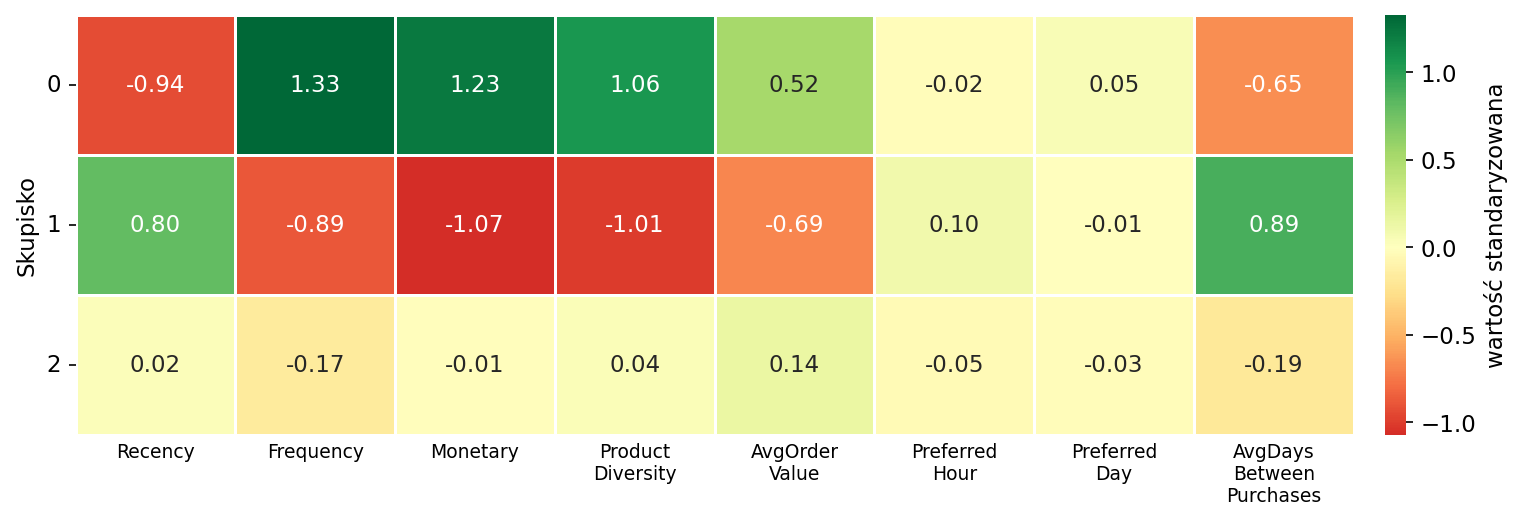

Zapisano: fig_profile_heatmap.png
  skupisko 0: zakres z-score [-0.94; 1.33]
  skupisko 1: zakres z-score [-1.07; 0.89]
  skupisko 2: zakres z-score [-0.19; 0.14]


In [10]:
# Mapa cieplna profili skupisk -- bez tytulu nad wykresem.
# Dlugie nazwy cech lamane na kilka linii, zeby etykiety byly poziome.
scaled_cols = pd.read_csv('rfm_scaled.csv').columns.tolist()
rfm_scaled_df = pd.read_csv('rfm_scaled.csv')
rfm_scaled_df['cluster_kmeans'] = km_labels

profile_scaled = rfm_scaled_df.groupby('cluster_kmeans')[scaled_cols].mean()

etykiety = {
    'Recency': 'Recency', 'Frequency': 'Frequency', 'Monetary': 'Monetary',
    'ProductDiversity': 'Product\nDiversity', 'AvgOrderValue': 'AvgOrder\nValue',
    'PreferredHour': 'Preferred\nHour', 'PreferredDay': 'Preferred\nDay',
    'AvgDaysBetweenPurchases': 'AvgDays\nBetween\nPurchases',
}
profile_plot = profile_scaled.rename(columns=etykiety)

fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(profile_plot, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            linewidths=0.5, ax=ax, annot_kws={'fontsize': 11},
            cbar_kws={'label': 'wartość standaryzowana', 'pad': 0.02})
ax.set_ylabel('Skupisko')
ax.set_xlabel('')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=9)
ax.tick_params(axis='x', length=0)
plt.tight_layout()
plt.savefig('fig_profile_heatmap.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_profile_heatmap.png')

# Zakres wartosci dla skupiska resztowego -- cytowany w rozdz. 5.1.2
for c in profile_scaled.index:
    w = profile_scaled.loc[c]
    print(f'  skupisko {c}: zakres z-score [{w.min():.2f}; {w.max():.2f}]')

## 6. Zapis wyników do cluster_labels.csv

In [11]:
output = rfm[['Customer ID', 'cluster_kmeans', 'cluster_dbscan']].copy()
output.to_csv('cluster_labels.csv', index=False)
print(f'Zapisano: cluster_labels.csv ({len(output)} wierszy)')
print(output.head())
print('\nRozkład skupisk k-średnich:')
print(output['cluster_kmeans'].value_counts().sort_index())

Zapisano: cluster_labels.csv (5859 wierszy)
   Customer ID  cluster_kmeans  cluster_dbscan
0        12346               2              -1
1        12347               0              -1
2        12348               2              -1
3        12349               0              -1
4        12350               1               0

Rozkład skupisk k-średnich:
cluster_kmeans
0    1467
1    1663
2    2729
Name: count, dtype: int64


## 7. Generowanie figur dla LaTeXa (histogramy + sezonowość)

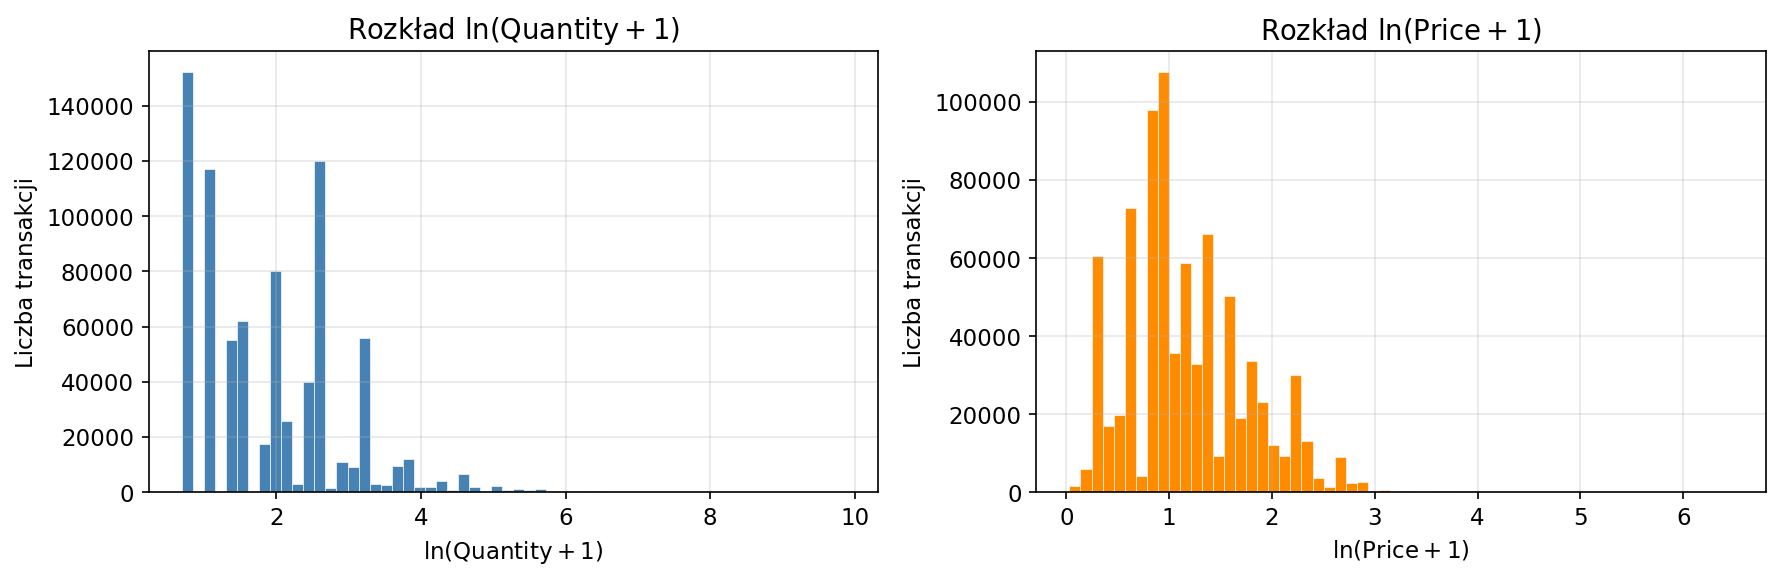

Zapisano: fig_hist_qty_price.png


In [12]:
# Histogramy Quantity i Price (skala log) — fig_hist_qty_price.png
df_clean = pd.read_csv('online_retail_clean.csv',
                       parse_dates=['InvoiceDate'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(np.log1p(df_clean['Quantity']), bins=60,
             color='steelblue', edgecolor='white', linewidth=0.3)
axes[0].set_title('Rozkład $\\ln(\\mathrm{Quantity}+1)$')
axes[0].set_xlabel('$\\ln(\\mathrm{Quantity}+1)$')
axes[0].set_ylabel('Liczba transakcji')
axes[0].grid(alpha=0.3)

axes[1].hist(np.log1p(df_clean['Price']), bins=60,
             color='darkorange', edgecolor='white', linewidth=0.3)
axes[1].set_title('Rozkład $\\ln(\\mathrm{Price}+1)$')
axes[1].set_xlabel('$\\ln(\\mathrm{Price}+1)$')
axes[1].set_ylabel('Liczba transakcji')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_hist_qty_price.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_hist_qty_price.png')

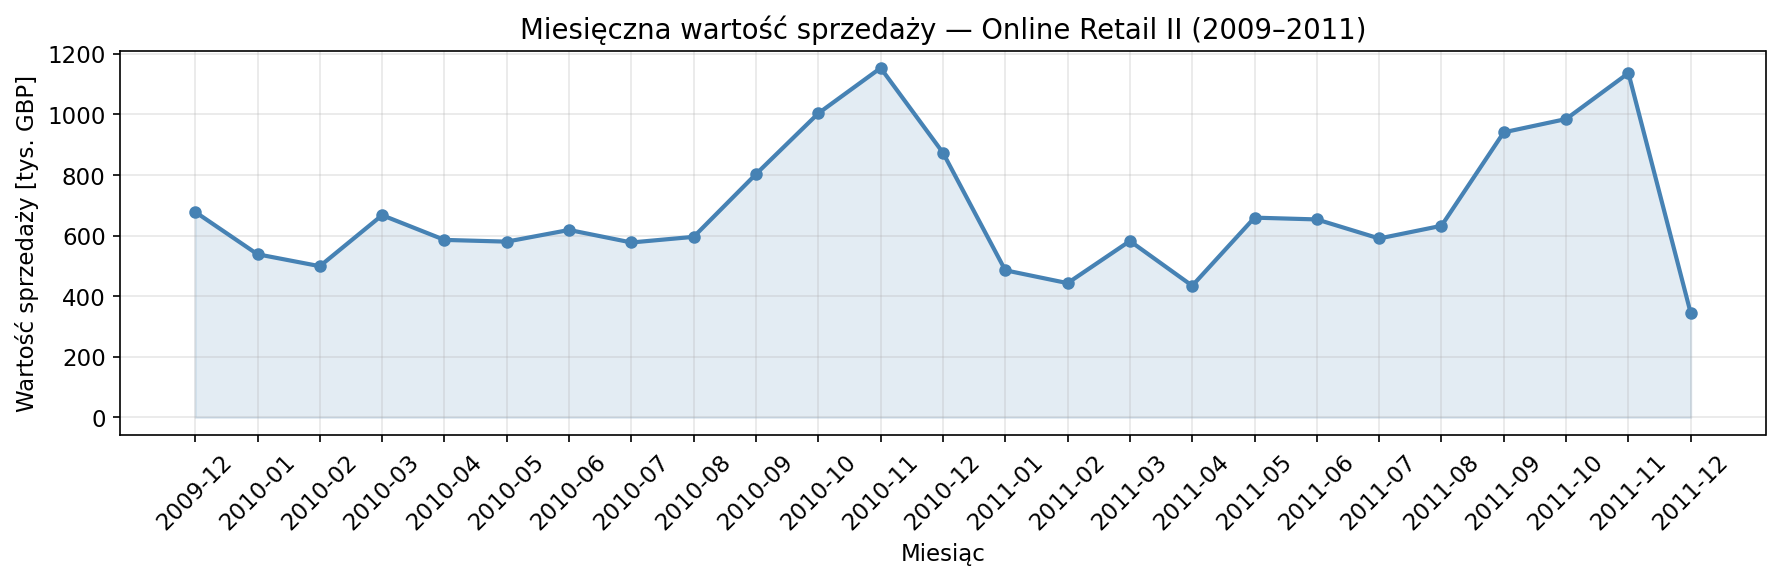

Zapisano: fig_sezonowosc.png


In [13]:
# Sezonowość sprzedaży miesięcznej — fig_sezonowosc.png
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['Price']
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
monthly = df_clean.groupby('YearMonth')['TotalPrice'].sum() / 1000  # tys. GBP

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index.astype(str), monthly.values,
        marker='o', color='steelblue', linewidth=2, markersize=5)
ax.fill_between(range(len(monthly)), monthly.values, alpha=0.15, color='steelblue')
ax.set_title('Miesięczna wartość sprzedaży — Online Retail II (2009–2011)')
ax.set_xlabel('Miesiąc')
ax.set_ylabel('Wartość sprzedaży [tys. GBP]')
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_sezonowosc.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_sezonowosc.png')